# Chặng 5 và 12 — EDA ba bộ dữ liệu

Notebook phân tích khám phá dữ liệu: CIC-IDS2017 (cửa sổ host 10 giây), CTU-13 (host–cửa sổ 120 giây) và lab ảo.
Giải thích chi tiết ở `docs/31_eda.md` và `docs/81_eda_tong_hop.md`. Mã: `src/nids/eda.py`, `src/nids/eda_tong_hop.py`.

**Chống rò rỉ:** thống kê theo nhãn chỉ dùng tập train.

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
F = ROOT / "output" / "features"
H = ROOT / "docs" / "hinh"

from nids.dataset import feature_columns, load_table
win = load_table([str(F / s) for s in ("cic17_monday", "cic17_wednesday", "cic17_friday")], "windows")
feats = feature_columns("windows")
print(len(win), "cửa sổ;", len(feats), "đặc trưng")

465393 cửa sổ; 20 đặc trưng


## 1. Phân bố lớp theo tập: mất cân bằng nặng

In [2]:
sure = win[win["split"].isin(["train", "validation", "test"]) & win["label_attack"].isin(["benign", "port_scan", "dos"])]
pd.crosstab(sure["label_attack"], sure["split"], margins=True)

split,test,train,validation,All
label_attack,,,,
benign,99988,252221,84958,437167
dos,727,2270,648,3645
port_scan,220,707,164,1091
All,100935,255198,85770,441903


## 2. Chất lượng dữ liệu (train): ô trống, giá trị vô hạn, trùng lặp

In [3]:
tr = sure[sure["split"] == "train"]
X = tr[feats].apply(pd.to_numeric, errors="coerce")
q = pd.DataFrame({"ty_le_trong": X.isna().mean(), "ty_le_bang_0": (X == 0).mean(),
                  "so_vo_han": np.isinf(X.to_numpy(float)).sum(0)})
print("Cửa sổ train trùng hệt cả đặc trưng lẫn nhãn:", round(tr.duplicated(subset=feats + ["label_attack"]).mean(), 3))
q.round(3)

Cửa sổ train trùng hệt cả đặc trưng lẫn nhãn: 0.461


,ty_le_trong,ty_le_bang_0,so_vo_han
packets_out,0.000,0.029,0
packets_in,0.000,0.017,0
bytes_out,0.000,0.029,0
bytes_in,0.000,0.017,0
dst_hosts,0.000,0.135,0
dst_ports,0.000,0.136,0
dst_host_ports,0.000,0.136,0
new_conn_out,0.000,0.659,0
src_hosts,0.000,0.721,0
new_conn_in,0.000,0.816,0


## 3. Thống kê mô tả và độ lệch: đặc trưng đếm lệch phải rất mạnh nên phải lấy log

In [4]:
X.describe(percentiles=[0.5, 0.99]).T.assign(skew=X.skew()).round(2)

,count,mean,std,min,50%,99%,max,skew
packets_out,255198.0,254.14,1611.41,0.0,20.00,3686.03,3.342500e+04,11.03
packets_in,255198.0,298.11,2027.82,0.0,20.00,4548.03,4.280300e+04,11.23
bytes_out,255198.0,44124.07,780142.64,0.0,2028.00,493872.82,3.079593e+07,35.79
bytes_in,255198.0,469517.53,4549894.09,0.0,1963.00,6226674.17,1.199974e+08,13.57
dst_hosts,255198.0,8.57,15.20,0.0,2.00,73.00,2.010000e+02,3.45
dst_ports,255198.0,2.03,15.56,0.0,2.00,5.00,9.980000e+02,63.49
dst_host_ports,255198.0,9.13,22.07,0.0,2.00,77.00,9.980000e+02,23.09
new_conn_out,255198.0,11.51,129.54,0.0,0.00,201.00,7.987000e+03,41.76
src_hosts,255198.0,0.53,1.15,0.0,0.00,5.00,1.100000e+01,3.02
new_conn_in,255198.0,8.09,126.99,0.0,0.00,135.00,7.991000e+03,44.31


## 4. Trung vị theo lớp: tấn công khác bình thường ở đâu

In [5]:
tr.groupby("label_attack")[["packets_in", "new_conn_in", "new_conn_out", "dst_ports", "dst_port_entropy",
                              "tcp_attempts_in", "incomplete_ratio_out", "src_hosts"]].median().T

label_attack,benign,dos,port_scan
packets_in,19.000000,284.000000,23.000000
new_conn_in,0.000000,2.500000,4.000000
new_conn_out,0.000000,0.000000,4.000000
dst_ports,2.000000,1.000000,2.000000
dst_port_entropy,0.623086,0.000000,1.456118
tcp_attempts_in,0.000000,2.500000,0.000000
incomplete_ratio_out,0.000000,0.045431,0.994985
src_hosts,0.000000,1.000000,1.000000


## 5. Hình đã vẽ: theo lớp, tương quan, AUC một biến, lệch CIC–lab

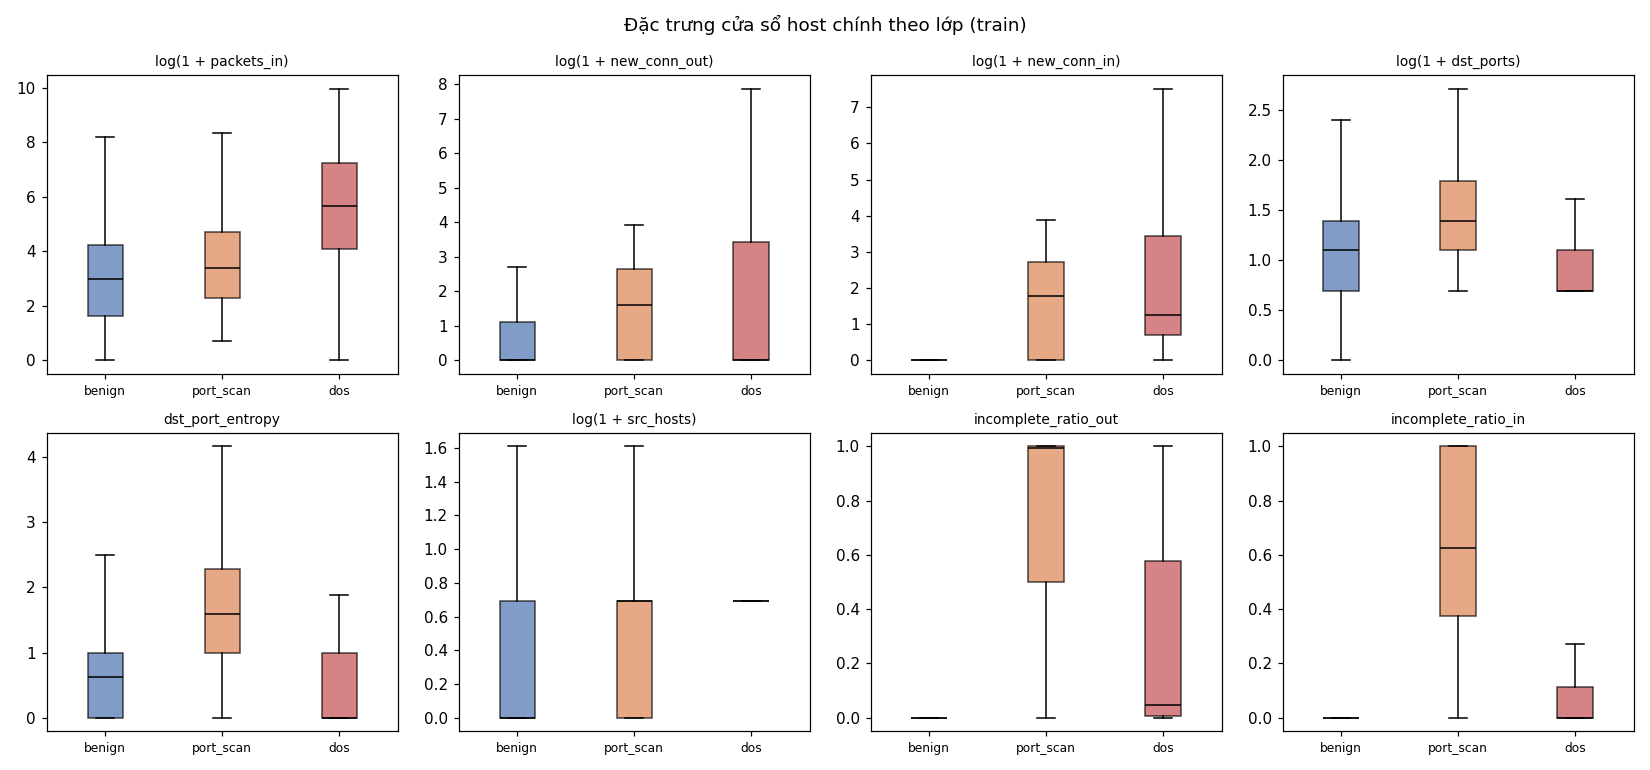

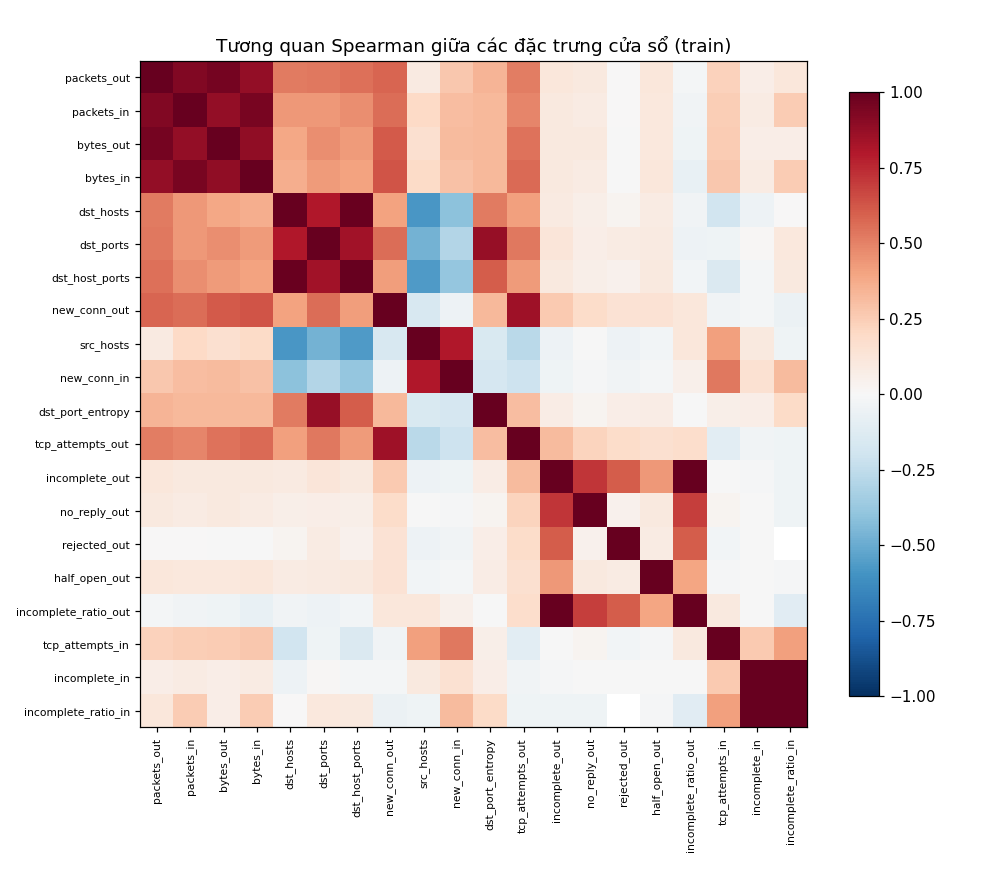

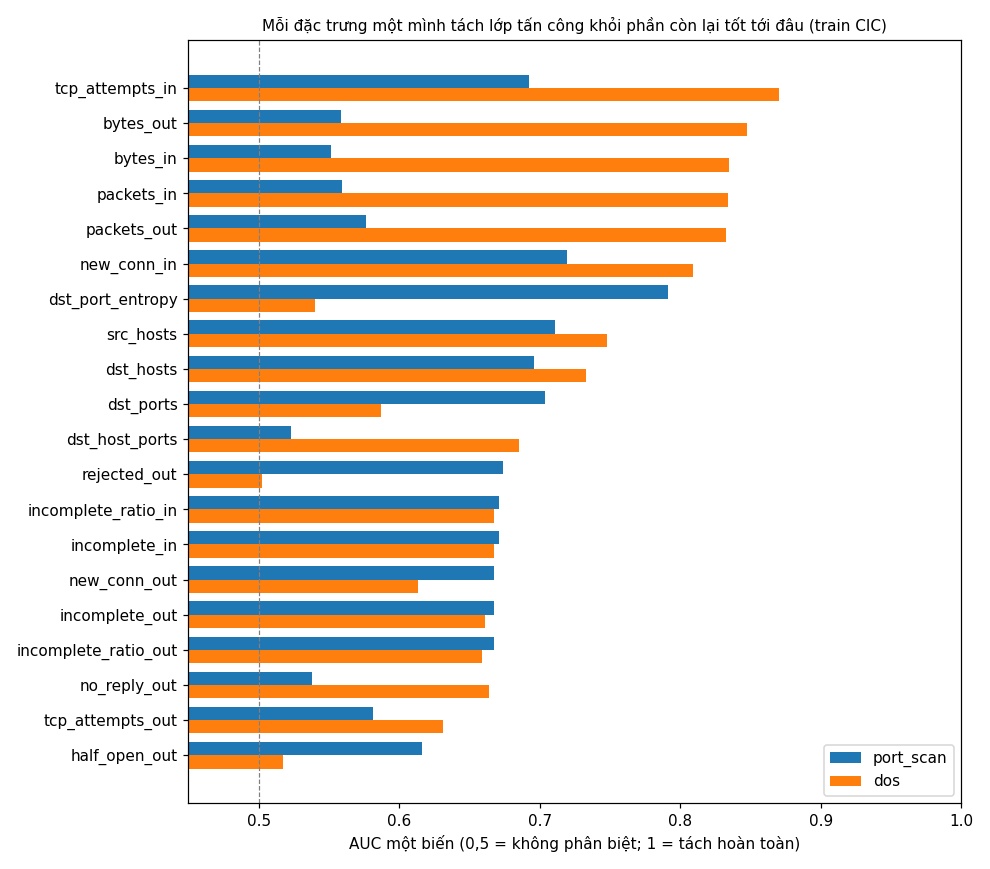

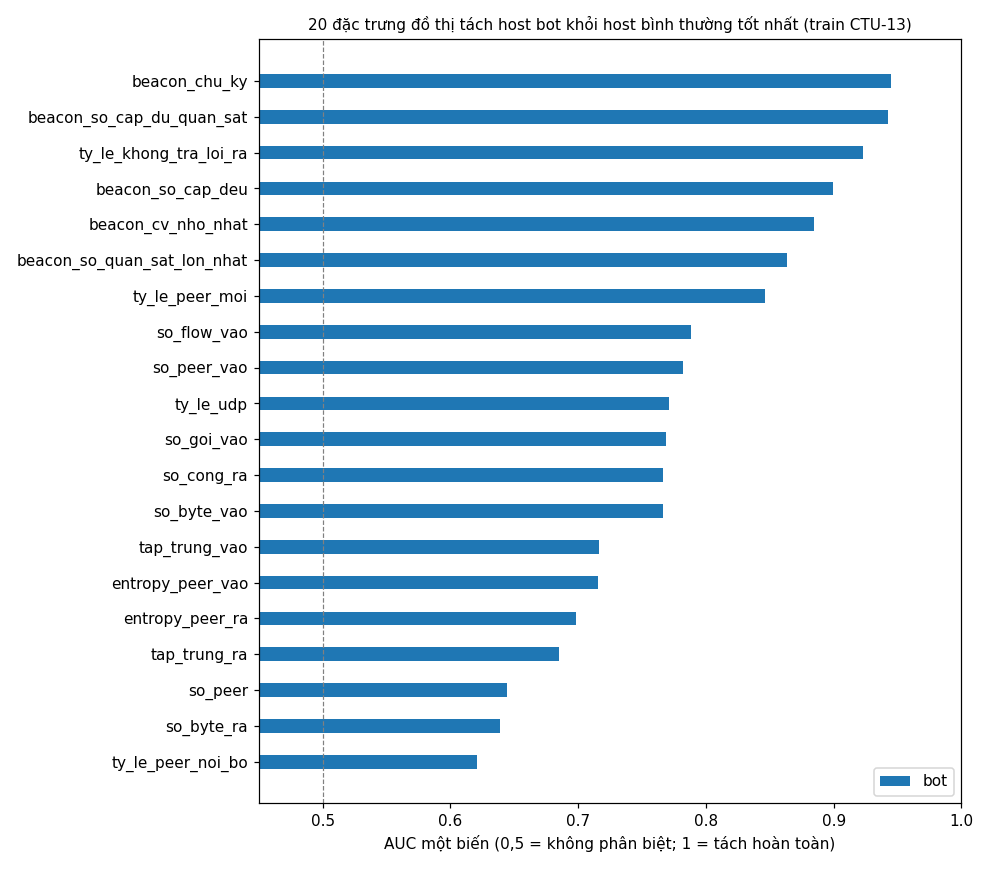

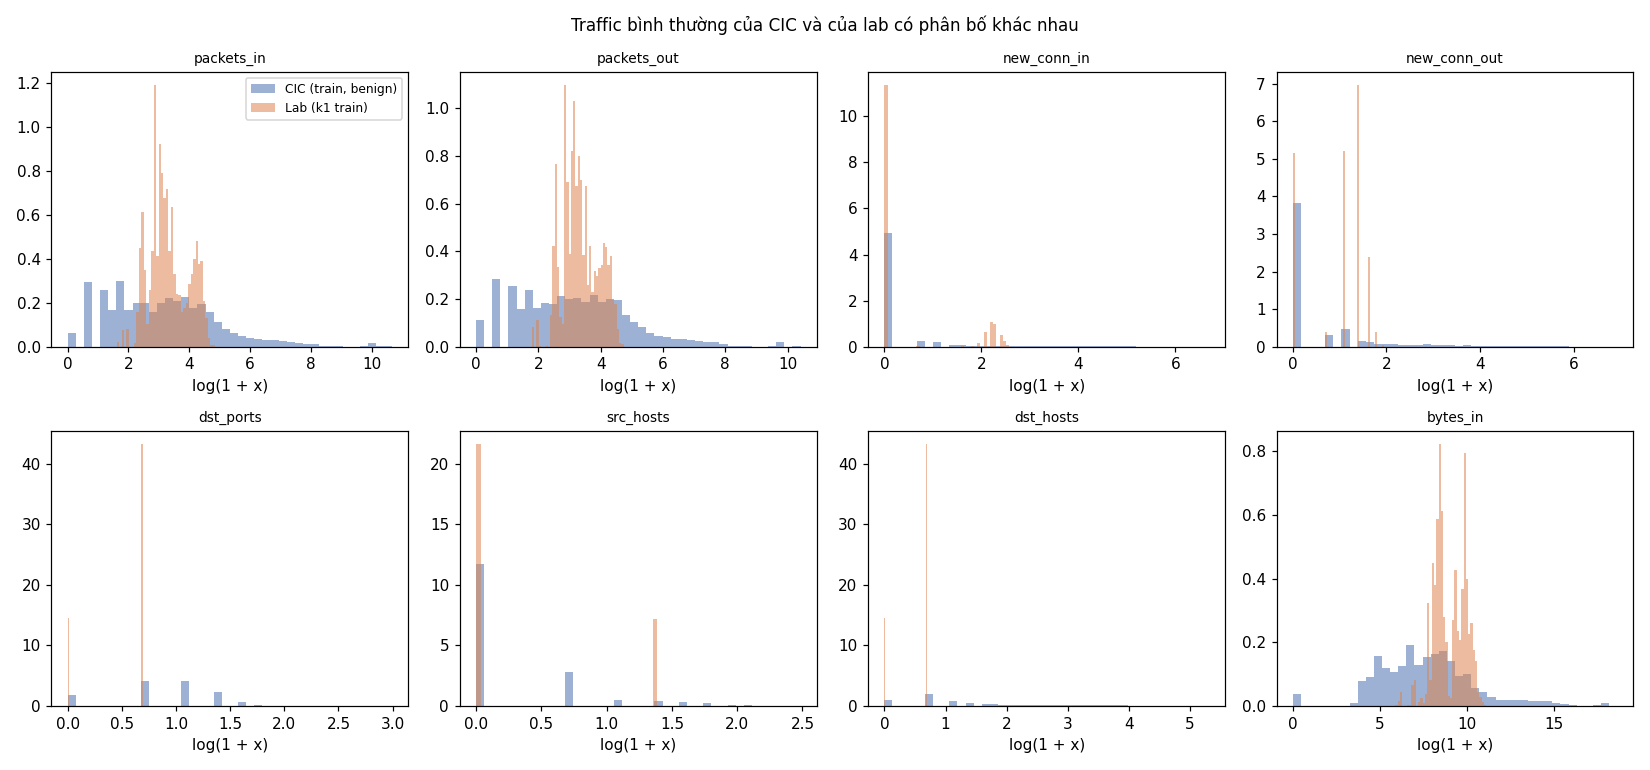

In [6]:
for f in ("eda_cua_so_theo_lop.png", "eda_tuong_quan_cua_so.png", "eda_tong_hop/cic_auc_dac_trung.png",
          "eda_tong_hop/ctu13_auc_dac_trung.png", "eda_tong_hop/lech_cic_lab.png"):
    display(Image(filename=str(H / f)))

## 6. Tóm tắt số liệu EDA tổng hợp

In [7]:
e = json.loads((H / "eda_tong_hop" / "eda_tong_hop.json").read_text(encoding="utf-8"))
print("Mất cân bằng train:", e["cic"]["mat_can_bang_train"])
print("CTU-13 theo tập:", e["ctu13"]["theo_tap_nhan"])
pd.DataFrame(e["lab"]["trung_vi_binh_thuong"]).T

Mất cân bằng train: {'benign_tren_dos': 111.1, 'benign_tren_port_scan': 356.7}
CTU-13 theo tập: {'test': {'background': 148720, 'normal_host': 24880, 'suspect_host': 19188, 'bo': 6489}, 'train': {'background': 183958, 'normal_host': 32827, 'bo': 11977, 'suspect_host': 9575}, 'validation': {'background': 60131, 'normal_host': 10453, 'suspect_host': 6555, 'bo': 1231}}


,cic,lab
packets_in,19.0,23.0
packets_out,20.0,26.0
new_conn_in,0.0,0.0
new_conn_out,0.0,2.0
dst_ports,2.0,1.0
src_hosts,0.0,0.0
dst_hosts,2.0,1.0
bytes_in,1902.0,6344.5
